# 第一个 OFDM 软件回环实验

今天的目标是让已知比特经过 QPSK → 子载波映射 → IFFT → CP → 模拟信道 → 去 CP → FFT → 均衡 → 比特判决，并统计错误。

本实验只使用 NumPy 和 Matplotlib，运行在板卡 ARM 或电脑的 Python 中。所有信号由软件生成，执行全部单元格即可。

**模型假设**：接收端已知符号起点和信道响应，收发采样时钟一致，频偏为零。导频先作为固定符号放入网格，均衡使用已知信道响应。实际射频演示还包含同步、频偏补偿和信道估计。

软件参数选用 64 点 FFT、16 点 CP、48 个数据子载波和 4 个导频，便于对照厂家 OFDM。此处的 20 MS/s 是明确设定的软件采样率，板端各采集点的实际采样率另行核对。

## 1. 设置参数
每个 QPSK 符号携带两个比特，每个 OFDM 符号有 48 个数据子载波，因此携带 96 个数据比特。IFFT 将整组子载波转换成 64 个时域采样，CP 再增加 16 个采样。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

FFT_SIZE = 64
CP_LENGTH = 16
SAMPLE_RATE = 20e6
NUM_SYMBOLS = 200
SNR_DB = 20
rng = np.random.RandomState(20261114)

active_carriers = np.r_[np.arange(-26, 0), np.arange(1, 27)]
pilot_carriers = np.array([-21, -7, 7, 21])
data_carriers = active_carriers[~np.isin(active_carriers, pilot_carriers)]
data_indices = data_carriers % FFT_SIZE
pilot_indices = pilot_carriers % FFT_SIZE
assert len(data_carriers) == 48
print('Data / pilot / null carriers:', len(data_carriers), len(pilot_carriers), FFT_SIZE - len(active_carriers))
print('Subcarrier spacing: %.1f kHz' % (SAMPLE_RATE / FFT_SIZE / 1e3))
print('Useful symbol / CP: %.1f / %.1f us' % (FFT_SIZE / SAMPLE_RATE * 1e6, CP_LENGTH / SAMPLE_RATE * 1e6))


Data / pilot / null carriers: 48 4 12
Subcarrier spacing: 312.5 kHz
Useful symbol / CP: 3.2 / 0.8 us


## 2. 产生发射波形
QPSK 将两比特映射到一个复数，实部和虚部各表示一个比特。子载波编号中的 0 是直流空载波。`ifft` 使用单位化形式，接收 `fft` 采用相同约定。CP 复制每个时域符号的末尾采样。

In [2]:
tx_bits = rng.randint(0, 2, size=(NUM_SYMBOLS, len(data_carriers), 2))
tx_symbols = ((1 - 2 * tx_bits[:, :, 0]) + 1j * (1 - 2 * tx_bits[:, :, 1])) / np.sqrt(2)
resource_grid = np.zeros((NUM_SYMBOLS, FFT_SIZE), dtype=np.complex128)
resource_grid[:, data_indices] = tx_symbols
resource_grid[:, pilot_indices] = 1
time_symbols = np.fft.ifft(resource_grid, axis=1, norm='ortho')
tx_blocks = np.concatenate([time_symbols[:, -CP_LENGTH:], time_symbols], axis=1)
tx_waveform = tx_blocks.ravel()
assert np.allclose(tx_blocks[:, :CP_LENGTH], time_symbols[:, -CP_LENGTH:])
print('Payload bits:', tx_bits.size)
print('Time samples including CP:', tx_waveform.size)


Payload bits: 19200
Time samples including CP: 16000


## 3. 模拟信道和接收机
多径由几个不同延迟、幅度和相位的副本叠加形成。CP 覆盖信道记忆长度后，FFT 输出可按每个子载波的信道响应进行均衡。这里使用已知响应 `H` 做零迫均衡。

SNR 按信道输出的平均时域信号功率与复噪声功率之比定义。EVM 使用已知且对齐的发射数据符号作为参考。

In [3]:
channel = np.array([1.0, 0, 0.6 * np.exp(0.7j), 0, 0.25 * np.exp(-0.4j)])
assert CP_LENGTH >= len(channel) - 1

def receive(channel_taps, snr_db=None):
    rx = np.convolve(tx_waveform, channel_taps)[:tx_waveform.size]
    if snr_db is not None:
        noise_power = np.mean(np.abs(rx)**2) / (10**(snr_db / 10))
        noise = np.sqrt(noise_power / 2) * (rng.randn(rx.size) + 1j * rng.randn(rx.size))
        rx = rx + noise
    rx_blocks = rx.reshape(NUM_SYMBOLS, FFT_SIZE + CP_LENGTH)
    rx_bins = np.fft.fft(rx_blocks[:, CP_LENGTH:], axis=1, norm='ortho')
    raw_data = rx_bins[:, data_indices]
    response = np.fft.fft(channel_taps, FFT_SIZE)[data_indices]
    equalized = raw_data / response
    return raw_data, equalized

def metrics(received):
    rx_bits = np.stack([received.real < 0, received.imag < 0], axis=-1)
    errors = np.count_nonzero(rx_bits != tx_bits)
    ber = errors / tx_bits.size
    evm = 100 * np.sqrt(np.mean(np.abs(received - tx_symbols)**2) / np.mean(np.abs(tx_symbols)**2))
    return errors, ber, evm


## 4. 检查是否正确收回数据
先在理想信道验证，再加入无噪声多径，最后加入噪声。前两项应观测到零误码，并且均衡后的符号与发射符号在浮点误差范围内一致。最后一项以实际输出为准。

In [4]:
_, ideal = receive(np.array([1.0]))
_, multipath_clean = receive(channel)
raw_noisy, equalized_noisy = receive(channel, SNR_DB)
assert np.allclose(ideal, tx_symbols, atol=1e-12)
assert np.allclose(multipath_clean, tx_symbols, atol=1e-12)
assert metrics(ideal)[0] == 0
assert metrics(multipath_clean)[0] == 0
print('Case                          errors / bits       BER         EVM (%)')
for name, samples in [('Ideal', ideal), ('Multipath, no noise', multipath_clean), ('Multipath + noise, equalized', equalized_noisy)]:
    errors, ber, evm = metrics(samples)
    print('%-29s %5d / %d    %.3e    %.4f' % (name, errors, tx_bits.size, ber, evm))


Case                          errors / bits       BER         EVM (%)
Ideal                             0 / 19200    0.000e+00    0.0000
Multipath, no noise               0 / 19200    0.000e+00    0.0000
Multipath + noise, equalized      1 / 19200    5.208e-05    14.7136


## 5. 看懂四张图
左上是子载波网格，右上显示 CP 与有效符号，左下是接收端均衡前的星座，右下是均衡后的星座。图中英文标签用于兼容板卡自带字体。

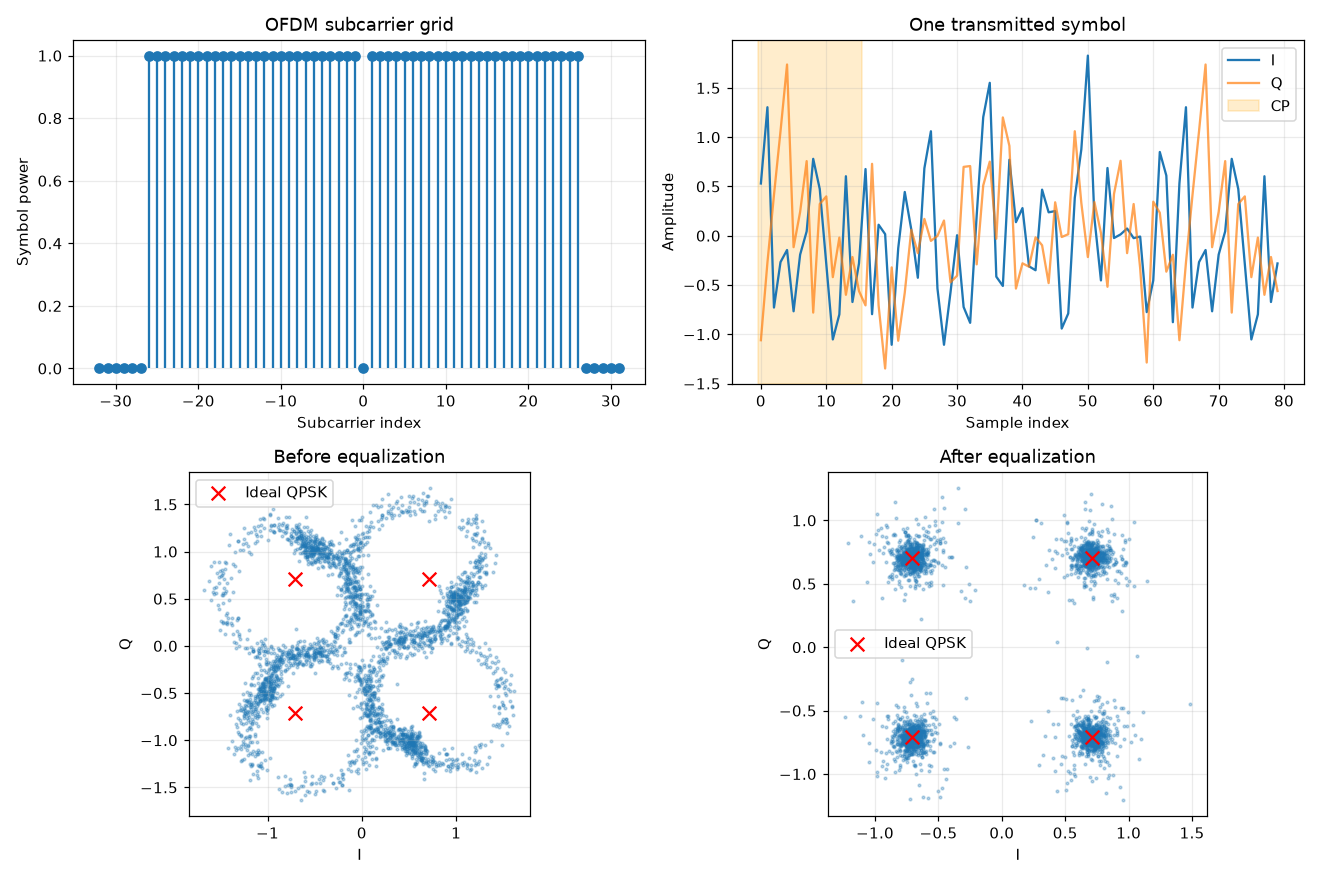

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].stem(np.arange(-FFT_SIZE // 2, FFT_SIZE // 2), np.abs(np.fft.fftshift(resource_grid[0]))**2, basefmt=' ')
axes[0, 0].set(title='OFDM subcarrier grid', xlabel='Subcarrier index', ylabel='Symbol power')
axes[0, 1].plot(tx_blocks[0].real, label='I')
axes[0, 1].plot(tx_blocks[0].imag, label='Q', alpha=0.7)
axes[0, 1].axvspan(-0.5, CP_LENGTH - 0.5, color='orange', alpha=0.2, label='CP')
axes[0, 1].set(title='One transmitted symbol', xlabel='Sample index', ylabel='Amplitude')
axes[0, 1].legend()
for ax, samples, title in [(axes[1, 0], raw_noisy, 'Before equalization'), (axes[1, 1], equalized_noisy, 'After equalization')]:
    points = samples.ravel()[:3000]
    ax.scatter(points.real, points.imag, s=3, alpha=0.3)
    ideal_points = np.unique(tx_symbols)
    ax.scatter(ideal_points.real, ideal_points.imag, marker='x', color='red', s=80, label='Ideal QPSK')
    ax.set(title=title, xlabel='I', ylabel='Q')
    ax.set_aspect('equal', adjustable='box')
    ax.legend()
for ax in axes.ravel():
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## 6. 今天完成什么

1. 上面的两项无噪声检查通过，理解每次比较了多少比特。
2. 将第 1 个代码单元格的 `SNR_DB` 从 20 改为 10，重新运行全部单元格，观察 EVM、误码和星座扩散。再改回 20。
3. 指出 IFFT、CP、去 CP、FFT 和均衡分别在哪一行代码。
4. 保存 Notebook 输出，记下参数和结果，明天与实际射频采集对照。

本次结果来自已知起点、已知信道的仿真。后续将依次加入前导同步、频偏估计、导频信道估计，再与 FPGA 数据通路对照。